In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("train.csv")

In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (159571, 8)


In [6]:
print("Columns:", df.columns.tolist())

Columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [7]:
df.head(9)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0


#### Checking Null Values:

In [8]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


#### Checking Duplicates:

In [9]:
print("Duplicate comment texts:",
      df["comment_text"].duplicated().sum())

Duplicate comment texts: 0


In [10]:
# 3. Label distribution
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print("Positive examples per label:")
print(df[labels].sum().sort_values(ascending=False))
## rakhne ki trick:
## ascending=True → chhote se bade
## ascending=False → bade se chhote

Positive examples per label:
toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64


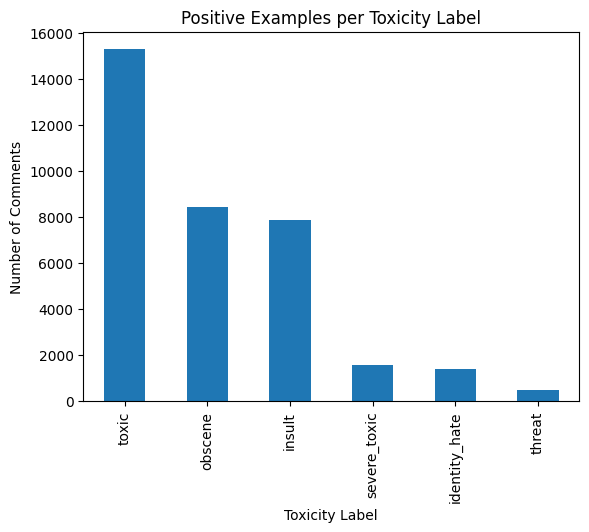

In [11]:
df[labels].sum().sort_values(ascending=False).plot(
    kind="bar",
    title="Positive Examples per Toxicity Label",
    xlabel="Toxicity Label",
    ylabel="Number of Comments"
)

plt.show()

In [12]:
df["any_toxic"] = df[labels].max(axis=1)

print(df["any_toxic"].value_counts())

any_toxic
0    143346
1     16225
Name: count, dtype: int64


#### note:
1. 1- km se km ek label positive h.
2. 0- saare 6 labels 0 h

In [13]:

# Character count and word count
df["char_count"] = df["comment_text"].str.len()
df["word_count"] = df["comment_text"].str.split().str.len()

# Summary statistics
display(df[["char_count", "word_count"]].describe())


,char_count,word_count
count,159571.000000,159571.000000
mean,394.073221,67.273527
std,590.720282,99.230702
min,6.000000,1.000000
25%,96.000000,17.000000
50%,205.000000,36.000000
75%,435.000000,75.000000
max,5000.000000,1411.000000


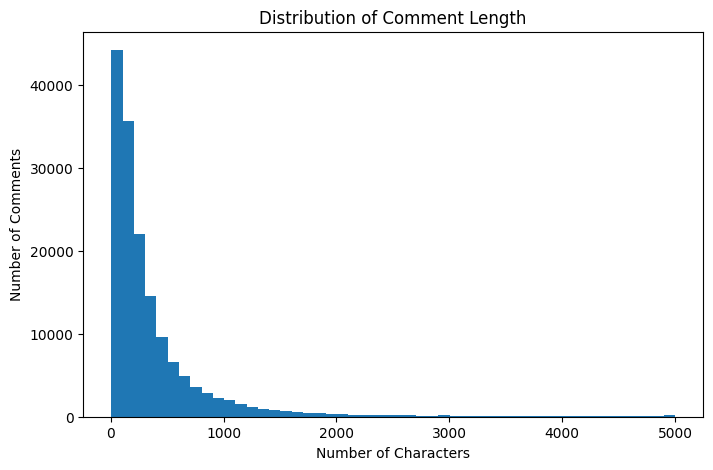

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["char_count"], bins=50)
plt.title("Distribution of Comment Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Comments")
plt.show()

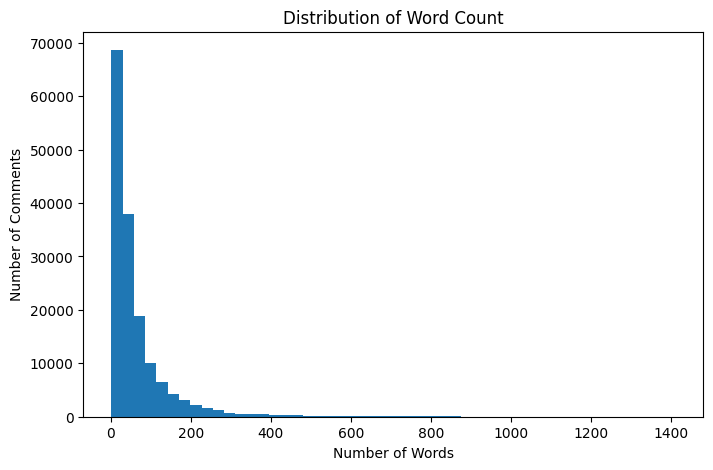

In [15]:

plt.figure(figsize=(8, 5))
plt.hist(df["word_count"], bins=50)
plt.title("Distribution of Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Comments")
plt.show()
